# key insight that should think befor weight initialize
1. Zero initialization: kono training hobe na
2. non-zero/constant initialization: multiple weight aksathe update hote thake, ete eita akta single perceptron modeler moto kaj kore, for that it will not able to captured non-linearity
3. Random initialization with small weights: random initialize korle "np.random.randn" diya er duita problem dekha jacchilo
   1. vanishing gradient problem
   2. slow convergence
4. Random initialization with large weights: eitaeo problem dekha jacchilo

# moral
SO moral of the story is: random weight initialize "random" diya korleo koto range er moddhe orthat "ato choto o na and ato boro o na" weight initialize korte hobe akta intermediate range er moddhe. ei theke eita buja gelo

# What can be done?

Eitar jonno kisu heuristics/practical solution ber kora hoise. 
  - Xavier/Glorat: best with "tanh activation"
  - HE: best with "relu activation"

And Xavier/Glorat and He are both have two types:
1. Normal
2. Uniform 

# intuition of random initialization

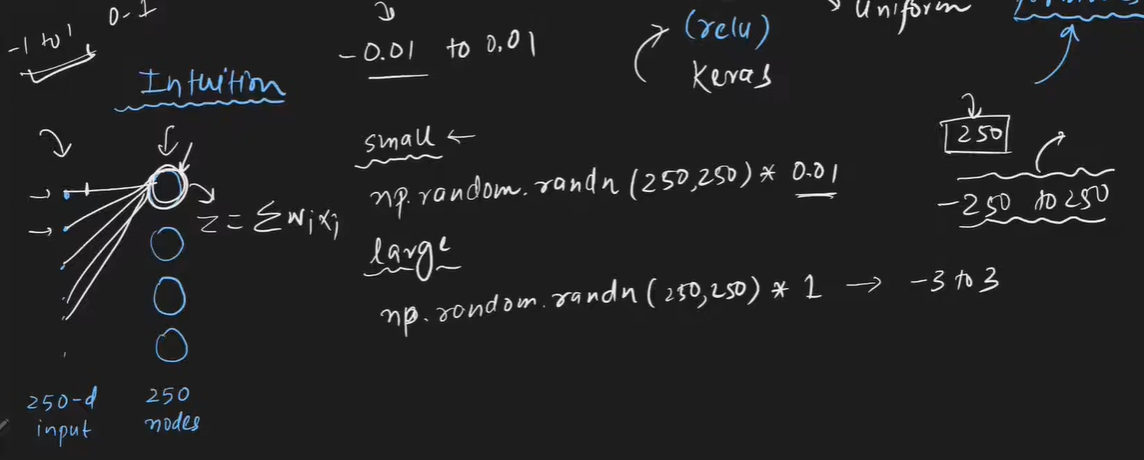

- random.randon er moddhe akta problem cilo ta hocche, akta contant value jokhon multiply kortam , tokohn ta hoito onk boro hoto na hoito onk choto hoito. jar jonno vanhising gradient and exploding gradient er moto problem dekha jaito. er solution hisebe amn akta rule ber korse jeno range ta intermediate range thake . erjonno random er sathe er variance ta hobe

- variance = 1/n ; n=total number of input jeita pichon theke aschete for specific nueron. orthat
- root(1/n); ja standard deviation

# Xavier/Glorat-Normal
- root(1/fan_in); fan_in = number of inputs coming to the nodes

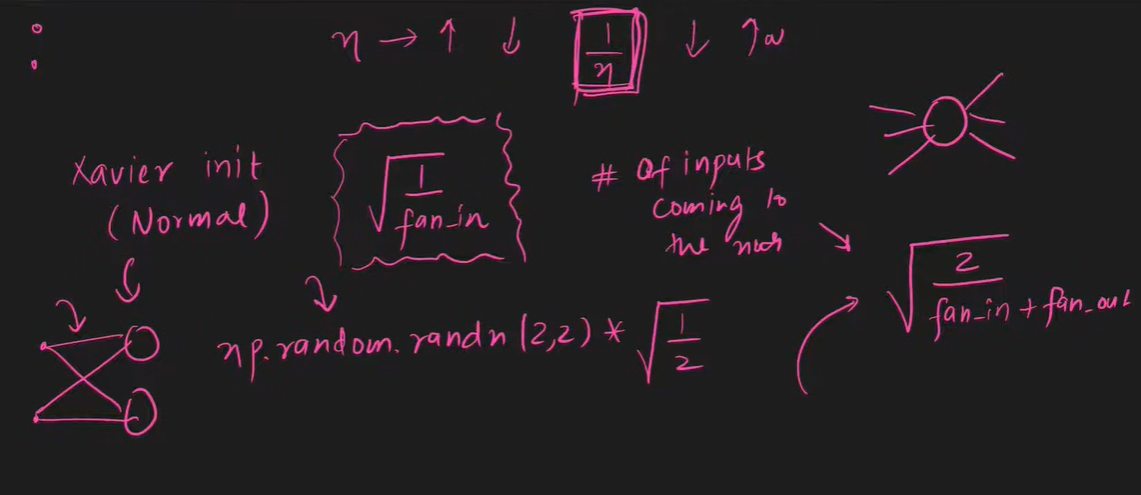

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input

In [29]:
df = pd.read_csv("files/ushape.csv")

In [30]:
df.head()

,X,Y,class
0,0.031595,0.986988,0.0
1,2.115098,-0.046244,1.0
2,0.882490,-0.075756,0.0
3,-0.055144,-0.037332,1.0
4,0.829545,-0.539321,1.0


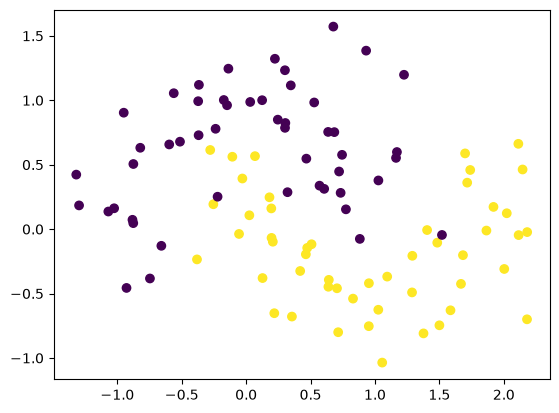

In [31]:
plt.scatter(df["X"], df["Y"], c=df["class"])

In [32]:
X = df.drop("class",axis=1)
y = df["class"]

In [16]:
model = Sequential()

model.add(Input(shape=(2,)))
model.add(Dense(10,activation="tanh"))
model.add(Dense(10,activation="tanh"))
model.add(Dense(10,activation="tanh"))
model.add(Dense(10,activation="tanh"))
model.add(Dense(1,activation="sigmoid"))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 371 (1.45 KB)

 Trainable params: 371 (1.45 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.get_weights()

[array([[-0.65090144,  0.35604495, -0.641183  , -0.6439359 , -0.17516434,
          0.583597  ,  0.5485361 , -0.24492073,  0.01274908,  0.68641335],
        [-0.45466232,  0.4843834 ,  0.51222295, -0.1129384 ,  0.571125  ,
         -0.3752356 ,  0.02367711,  0.4761911 ,  0.45972687, -0.696141  ]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 0.37017775, -0.13871369, -0.5072604 ,  0.2730937 ,  0.487185  ,
         -0.5051752 ,  0.48728383,  0.50671625, -0.49261412, -0.16561636],
        [ 0.02873623,  0.10391229,  0.08668643, -0.1365475 , -0.30445188,
          0.17205638,  0.4775715 ,  0.29199505, -0.35938495, -0.15310204],
        [ 0.44328988, -0.48940688,  0.07146215,  0.25527453,  0.41880894,
          0.25585645, -0.005373  , -0.4053834 , -0.45181134, -0.4341139 ],
        [-0.2530611 , -0.03364217,  0.5212847 ,  0.41906893,  0.38562948,
         -0.10743803, -0.11565551, -0.4940379 ,  0.13195264, -0.16794968],
        [ 0.03722

In [18]:
init_weight = model.get_weights()

In [19]:
init_weight[0] = np.random.randn(2,10)*np.sqrt(1/2)
init_weight[1] = np.zeros(model.get_weights()[1].shape)
init_weight[2] = np.random.randn(10,10)*np.sqrt(1/10)
init_weight[3] = np.zeros(model.get_weights()[3].shape)
init_weight[4] = np.random.randn(10,10)*np.sqrt(1/10)
init_weight[5] = np.zeros(model.get_weights()[5].shape)
init_weight[6] = np.random.randn(10,10)*np.sqrt(1/10)
init_weight[7] = np.zeros(model.get_weights()[7].shape)
init_weight[8] = np.random.randn(10,1)*np.sqrt(1/10)
init_weight[9] = np.zeros(model.get_weights()[9].shape)

In [20]:
model.set_weights(init_weight)

In [21]:
model.get_weights()

[array([[-0.63401383, -0.03195311, -0.08959251,  0.4896386 , -0.00748558,
         -0.13056746,  0.01387749,  0.7154196 , -0.714463  ,  0.46618   ],
        [-0.36614263,  0.00953797, -1.2243333 ,  0.1163478 ,  0.07224211,
         -0.47545826,  0.71976906,  0.04264973, -1.5390652 , -0.14814861]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 1.64297260e-02, -3.65189403e-01,  8.30866918e-02,
          7.69598782e-02,  4.57089007e-01, -4.48028922e-01,
         -5.34171402e-01,  4.66262549e-01, -1.52105868e-01,
         -8.19298685e-01],
        [ 2.96423495e-01, -4.93778139e-01, -2.19782829e-01,
         -2.48406440e-01,  3.10288854e-02, -2.14629218e-01,
         -8.38858187e-02,  9.34979022e-02, -2.38128066e-01,
         -6.26623854e-02],
        [ 8.29827935e-02, -7.54923165e-01,  2.62779593e-01,
         -2.45843157e-01,  2.57706225e-01, -8.66690353e-02,
         -2.00689211e-01,  1.71282843e-01, -1.51630312e-01,
          1.3194568

In [22]:
model.compile(loss="binary_crossentropy",optimizer="adam",metrics=["accuracy"])

In [23]:
history = model.fit(X,y,epochs=100, validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 135ms/step - accuracy: 0.2125 - loss: 0.7230 - val_accuracy: 0.1500 - val_loss: 0.7239
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.2625 - loss: 0.7123 - val_accuracy: 0.2000 - val_loss: 0.7114
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.3000 - loss: 0.7027 - val_accuracy: 0.3000 - val_loss: 0.6998
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.5375 - loss: 0.6934 - val_accuracy: 0.6500 - val_loss: 0.6897
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7125 - loss: 0.6848 - val_accuracy: 0.8000 - val_loss: 0.6796
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.7375 - loss: 0.6770 - val_accuracy: 0.8500 - val_loss: 0.6697
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.7750 - loss: 0.6690 - val_accuracy: 0.8500 - val_loss: 0.6601
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.8125 - loss: 0.6608 - val_accuracy: 0.8500 - val_loss

In [24]:
model.get_weights()

[array([[-0.66222924, -0.17133145, -0.00478336,  0.43948728,  0.11474022,
         -0.20018864, -0.163931  ,  0.548351  , -0.65473545,  0.4651446 ],
        [-0.21961528,  0.15921962, -1.321153  ,  0.01974268,  0.02546821,
         -0.38109297,  0.81591785,  0.02580808, -1.6301957 , -0.30881527]],
       dtype=float32),
 array([-0.08903265,  0.06319205,  0.08375496, -0.06701807, -0.02853817,
        -0.01083069, -0.06807686, -0.06727349,  0.14281325, -0.12990218],
       dtype=float32),
 array([[-0.07298445, -0.4079605 ,  0.03417423, -0.02055277,  0.5510595 ,
         -0.41595235, -0.5168476 ,  0.5006265 , -0.03809413, -0.8497961 ],
        [ 0.07928714, -0.71478975, -0.4273936 , -0.4571404 , -0.02951448,
         -0.39416155,  0.09891718,  0.3127377 , -0.00913848, -0.22843115],
        [ 0.18889715, -0.73781836,  0.33538374, -0.14707136,  0.3484012 ,
          0.0493832 , -0.29959738,  0.04699892, -0.2513964 ,  0.27530572],
        [ 0.04311001,  0.11499524,  0.42592686, -0.1276996 , 

In [25]:
from mlxtend.plotting import plot_decision_regions

class KerasWrapper:

    def __init__(self, model):
        self.model = model

    def predict(self, X):
        probabilities = self.model.predict(X, verbose=0)
        return (probabilities.ravel() > 0.5).astype(int)

clf = KerasWrapper(model)

<Axes: >

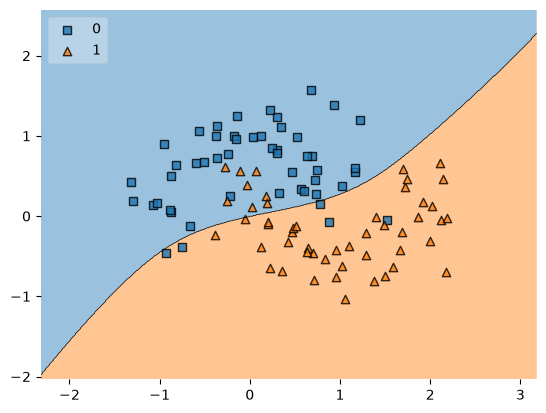

In [27]:
plot_decision_regions(X.values,y.astype("int").values, clf=clf, legend=2)

# weight initialization: HE-Normal

- He relu er sathe use kora hoy, normal type e Xavier er sathe just 1 er jaigai 2 hobe eituku parthokko


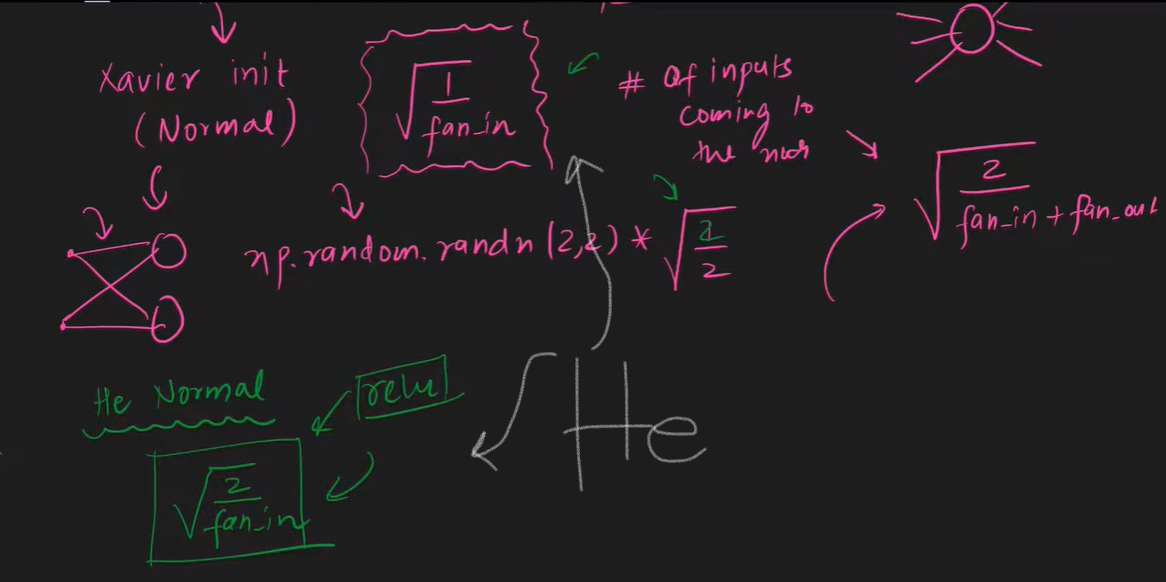

# Uniform distribution for Xavier

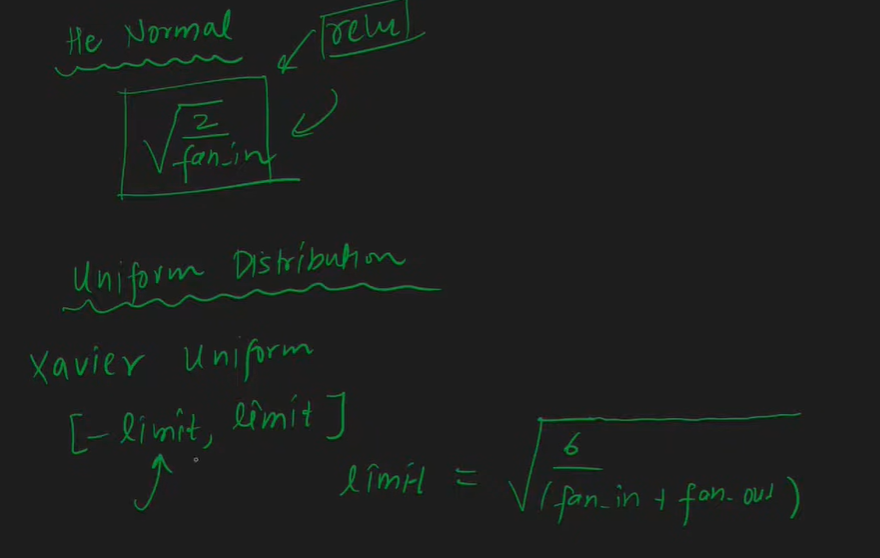

In [35]:
model = Sequential()
model.add(Input(shape=(2,)))
model.add(Dense(10,activation="relu", kernel_initializer="he_normal"))
model.add(Dense(10,activation="relu", kernel_initializer="he_normal"))
model.add(Dense(10,activation="relu", kernel_initializer="he_normal"))
model.add(Dense(10,activation="relu", kernel_initializer="he_normal"))
model.add(Dense(1,activation="sigmoid"))

In [36]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 371 (1.45 KB)

 Trainable params: 371 (1.45 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
model.get_weights()

[array([[ 1.3286653 ,  1.0284271 ,  1.5557412 ,  0.64757586, -1.413736  ,
         -0.8458359 , -0.6922243 , -0.48564318,  0.43976805, -0.6956909 ],
        [-1.80267   ,  0.08909573, -1.0846772 , -0.96467984, -0.19752647,
          1.0522949 ,  1.1709001 , -0.59331554, -0.8388244 ,  0.21508753]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.21070382,  0.3464555 , -0.51687026,  0.17575145, -0.3327606 ,
         -0.26677668,  0.844474  ,  0.34711078,  0.20909938, -0.13458112],
        [-0.59666914,  0.20152377,  0.5531461 ,  0.15658511,  0.42828035,
          0.4926841 , -0.44851837,  0.42930943,  0.2676499 , -0.07102142],
        [ 0.54433405,  0.11989295, -0.55705726, -0.06657162,  0.29837686,
          0.55968213,  0.8255663 , -0.5823291 , -0.21735333, -0.7255921 ],
        [-0.61324954, -0.30395103,  0.060925  ,  0.13475654, -0.73157513,
          0.20084746, -0.3861199 , -0.29893643,  0.48233762,  0.08952916],
        [ 0.86680

In [38]:
model.compile(loss='binary_crossentropy',optimizer="adam",metrics=["accuracy"])

In [39]:
history = model.fit(X,y,epochs=100, validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 437ms/step - accuracy: 0.5000 - loss: 0.8962 - val_accuracy: 0.5000 - val_loss: 0.8361
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.5000 - loss: 0.8390 - val_accuracy: 0.5000 - val_loss: 0.7754
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.5000 - loss: 0.7821 - val_accuracy: 0.4500 - val_loss: 0.7218
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.4750 - loss: 0.7288 - val_accuracy: 0.5000 - val_loss: 0.6746
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.5125 - loss: 0.6914 - val_accuracy: 0.6000 - val_loss: 0.6346
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.6375 - loss: 0.6532 - val_accuracy: 0.8000 - val_loss: 0.6021
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.8000 - loss: 0.6241 - val_accuracy: 0.8500 - val_loss: 0.5764
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 163ms/step - accuracy: 0.8000 - loss: 0.6034 - val_accuracy: 0.8500 - val_

In [40]:
model.get_weights()

[array([[ 1.2862192 ,  1.1041979 ,  1.5217991 ,  0.6663865 , -1.5328891 ,
         -0.6184277 , -0.82017386, -0.4717486 ,  0.48234865, -0.741968  ],
        [-1.9451604 ,  0.18203422, -1.1764861 , -1.0048537 , -0.24367973,
          1.230286  ,  1.0680306 , -0.6184896 , -0.8958095 ,  0.27773768]],
       dtype=float32),
 array([-0.09949689,  0.03877229, -0.05230631,  0.01293669,  0.04119235,
         0.0351036 , -0.02958582, -0.04523661,  0.09545477, -0.01036546],
       dtype=float32),
 array([[-0.21070382,  0.40278813, -0.47540691,  0.23195992, -0.2544739 ,
         -0.1130265 ,  0.8431798 ,  0.25120556,  0.241613  , -0.13458112],
        [-0.56087106,  0.12546131,  0.738177  ,  0.17513323,  0.6159147 ,
          0.46352398, -0.46033946,  0.56708825,  0.29353118, -0.07102142],
        [ 0.65246964,  0.12560414, -0.4257583 , -0.02415737,  0.43488327,
          0.67484665,  0.81851315, -0.5963792 , -0.18559687, -0.7255921 ],
        [-0.6826541 , -0.25126085,  0.12055154,  0.19088677, 

<Axes: >

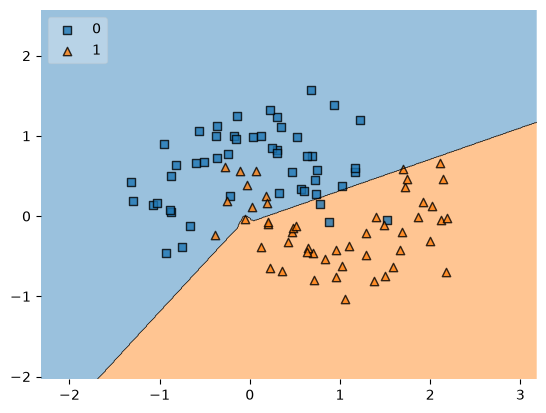

In [46]:
from mlxtend.plotting import plot_decision_regions
class kerasWrapper:
    def __init__(self,model):
        self.model = model

    def predict(self,X):
        pred = self.model.predict(X,verbose=0)
        return (pred > 0.5).astype(int).ravel()
clf = kerasWrapper(model)

plot_decision_regions(X.values,y.astype("int").values, clf=clf, legend=2)
    

# Uniform distrubuition of HE:
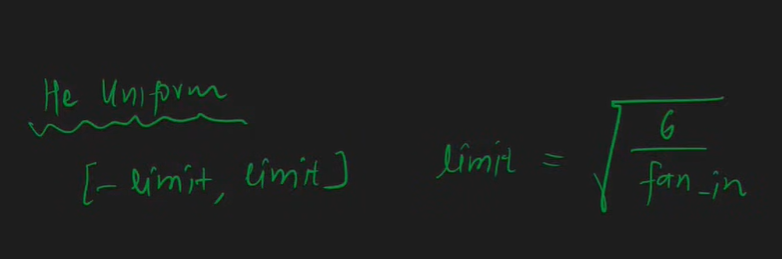